# Segmentasi Pelanggan E-Commerce Berdasarkan Karakteristik Perilaku Belanja dan Aktivitas Digital Menggunakan Algoritma Clustering untuk Strategi Personalisasi Pemasaran

# Profile Kelompok

1. Putri Asmiranti Samiun		(123240033)
2. Briliant Priscilla	  		(123240068)
3. Andini Papa Sulima 		(123240118)
4. Nathania Keyne Rahmawati 	(123240201)


# Data Understanding
Fase ini bertujuan untuk memahami karakteristik awal dari dataset, mendeteksi potensi masalah kualitas data, dan menemukan wawasan awal (*insights*) terkait perilaku pelanggan E-Commerce sebelum masuk ke tahap prapemrosesan dan pemodelan *clustering*.

## Latar Belakang & Tujuan Analisis
Pemahaman terhadap profil pelanggan (*Customer Profiling*) sangat krusial bagi bisnis *e-commerce* untuk mengidentifikasi kelompok pelanggan dengan karakteristik serupa. Melalui pendekatan *unsupervised learning* (Clustering), analisis ini bertujuan untuk mengelompokkan pelanggan berdasarkan metrik keterlibatan aplikasi, riwayat pesanan, dan karakteristik demografis, yang nantinya dapat dimanfaatkan oleh tim bisnis untuk merumuskan strategi personalisasi pemasaran (*targeted marketing*) serta menekan angka *churn*.

## Data dictionary (variabel, tipe, unit)
Tabel kamus data di bawah ini mendefinisikan seluruh variabel yang terdapat di dalam dataset *E-Commerce* (`E Comm` sheet), lengkap dengan tipe data asli dari sistem dan unit ukurannya:

| Kolom | Tipe | Unit | Keterangan |
| :--- | :--- | :--- | :--- |
| `CustomerID` | int64 | ID | ID unik pelanggan |
| `Churn` | int64 | Flag (0/1) | Penanda *churn* atau indikator pelanggan berhenti |
| `Tenure` | float64 | Bulan | Masa berlangganan pelanggan di dalam organisasi/perusahaan |
| `PreferredLoginDevice` | object | Kategori | Perangkat *login* yang lebih disukai atau sering digunakan pelanggan |
| `CityTier` | int64 | Tingkatan | Tingkatan atau kategori kota tempat tinggal pelanggan |
| `WarehouseToHome` | float64 | Kilometer / Mil | Jarak antara gudang pengiriman dengan rumah pelanggan |
| `PreferredPaymentMode` | object | Kategori | Metode pembayaran pilihan yang sering digunakan pelanggan |
| `Gender` | object | Kategori | Jenis kelamin pelanggan |
| `HourSpendOnApp` | float64 | Jam | Jumlah jam yang dihabiskan pelanggan pada aplikasi seluler atau situs web |
| `NumberOfDeviceRegistered` | int64 | Unit | Total perangkat yang didaftarkan oleh pelanggan tertentu |
| `PreferedOrderCat` | object | Kategori | Kategori pesanan yang menjadi preferensi pelanggan pada bulan lalu |
| `SatisfactionScore` | int64 | Skor (1-5) | Skor kepuasan pelanggan terhadap layanan yang diberikan |
| `MaritalStatus` | object | Kategori | Status pernikahan dari pelanggan |
| `NumberOfAddress` | int64 | Unit | Total alamat pengiriman yang ditambahkan oleh pelanggan tertentu |
| `Complain` | int64 | Flag (0/1) | Indikator apakah pelanggan pernah mengajukan keluhan pada bulan lalu |
| `OrderAmountHikeFromlastYear` | float64 | Persen (%) | Persentase peningkatan jumlah pesanan dibandingkan dengan tahun lalu |
| `CouponUsed` | float64 | Unit | Total kupon diskon yang telah digunakan pelanggan pada bulan lalu |
| `OrderCount` | float64 | Unit | Total pesanan yang telah berhasil dibuat pada bulan lalu |
| `DaySinceLastOrder` | float64 | Hari | Jumlah hari yang berlalu sejak pesanan terakhir pelanggan |
| `CashbackAmount` | float64 | Mata Uang | Rata-rata nominal *cashback* yang diterima pelanggan pada bulan lalu |

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OrdinalEncoder
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram

---
## Bagian 1: Data Ingestion 

Baca file `E_Commerce_Dataset.csv` ke dalam DataFrame `df`. Tampilkan 5 baris teratas dan ukuran data (jumlah baris dan kolom).

In [2]:
# Membaca file CSV ke dalam DataFrame df menggunakan pandas
df = pd.read_csv('E_Commerce_Dataset.csv')

# Menampilkan 5 baris teratas untuk inspeksi struktur data awal
display(df.head())

# Menampilkan ukuran data (jumlah baris dan kolom)
print("Ukuran data (baris, kolom):", df.shape)

,CustomerID,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
0,50001,1,4.0,Mobile Phone,3,6.0,Debit Card,Female,3.0,3,Laptop & Accessory,2,Single,9,1,11.0,1.0,1.0,5.0,160
1,50002,1,NaN,Phone,1,8.0,UPI,Male,3.0,4,Mobile,3,Single,7,1,15.0,0.0,1.0,0.0,121
2,50003,1,NaN,Phone,1,30.0,Debit Card,Male,2.0,4,Mobile,3,Single,6,1,14.0,0.0,1.0,3.0,120
3,50004,1,0.0,Phone,3,15.0,Debit Card,Male,2.0,4,Laptop & Accessory,5,Single,8,0,23.0,0.0,1.0,3.0,134
4,50005,1,0.0,Phone,1,12.0,CC,Male,NaN,3,Mobile,5,Single,3,0,11.0,1.0,1.0,3.0,130


Ukuran data (baris, kolom): (5630, 20)


Tampilkan informasi ringkas dataset. Sebutkan kolom yang tipe datanya kurang sesuai dan tipe yang seharusnya.

In [3]:
# Menampilkan informasi ringkas dataset (tipe data, non-null count)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5630 entries, 0 to 5629
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   CustomerID                   5630 non-null   int64  
 1   Churn                        5630 non-null   int64  
 2   Tenure                       5366 non-null   float64
 3   PreferredLoginDevice         5630 non-null   str    
 4   CityTier                     5630 non-null   int64  
 5   WarehouseToHome              5379 non-null   float64
 6   PreferredPaymentMode         5630 non-null   str    
 7   Gender                       5630 non-null   str    
 8   HourSpendOnApp               5375 non-null   float64
 9   NumberOfDeviceRegistered     5630 non-null   int64  
 10  PreferedOrderCat             5630 non-null   str    
 11  SatisfactionScore            5630 non-null   int64  
 12  MaritalStatus                5630 non-null   str    
 13  NumberOfAddress              

---
## Bagian 2: Data Preprocessing

Tampilkan jumlah missing value pada setiap kolom dan jumlah baris duplikat.

In [4]:
# Menampilkan missing value per kolom
print("Jumlah missing value per kolom:\n", df.isnull().sum())

# Menampilkan jumlah baris duplikat
print("\nJumlah baris duplikat:", df.duplicated().sum())

Jumlah missing value per kolom:
 CustomerID                       0
Churn                            0
Tenure                         264
PreferredLoginDevice             0
CityTier                         0
WarehouseToHome                251
PreferredPaymentMode             0
Gender                           0
HourSpendOnApp                 255
NumberOfDeviceRegistered         0
PreferedOrderCat                 0
SatisfactionScore                0
MaritalStatus                    0
NumberOfAddress                  0
Complain                         0
OrderAmountHikeFromlastYear    265
CouponUsed                     256
OrderCount                     258
DaySinceLastOrder              307
CashbackAmount                   0
dtype: int64

Jumlah baris duplikat: 0


----
Karena tidak ada data duplikat, tangani missing value pada kolom (boleh diisi mean, median, modus, atau baris dihapus). Tampilkan bukti bahwa data tidak lagi memiliki missing value.

In [5]:
# Pastikan df_clean sudah terdefinisi dari file CSV
df_clean = pd.read_csv('E_Commerce_Dataset.csv')

# Menangani missing value pada kolom numerik menggunakan nilai median masing-masing kolom
cols_to_fill = [
    'Tenure', 'WarehouseToHome', 'HourSpendOnApp', 
    'OrderAmountHikeFromlastYear', 'CouponUsed', 'OrderCount', 'DaySinceLastOrder'
]

for col in cols_to_fill:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median()) #mengisi missing value dengan median

# Membuktikan bahwa seluruh kolom sudah bersih dari missing value
print("Jumlah missing value per kolom setelah ditangani:\n", df_clean[cols_to_fill].isnull().sum())

Jumlah missing value per kolom setelah ditangani:
 Tenure                         0
WarehouseToHome                0
HourSpendOnApp                 0
OrderAmountHikeFromlastYear    0
CouponUsed                     0
OrderCount                     0
DaySinceLastOrder              0
dtype: int64


Saya memilih metode imputasi menggunakan median untuk kolom Income. Alasannya:

- Data tersebut umumnya memiliki distribusi yang menceng (skewed) karena adanya nilai ekstrem atau outliers berupa pendapatan yang sangat tinggi.

- Berbeda dengan mean (rata-rata) yang sangat sensitif dan mudah tertarik oleh nilai ekstrem, median (nilai tengah) jauh lebih tahan bermanuver (robust) sehingga nilai pengganti untuk data yang kosong tetap mencerminkan kondisi pendapatan tipikal sebagian besar pelanggan.

---
Buat **boxplot** untuk kolom `CashbackAmount` dan `Tenure` (dua panel berdampingan, lengkap dengan judul). Lalu jawab:

(a) Apa yang bisa kamu simpulkan dari boxplot tersebut?

(b) Apakah ada outlier? Jika ada, di kolom mana dan kira-kira bernilai berapa?


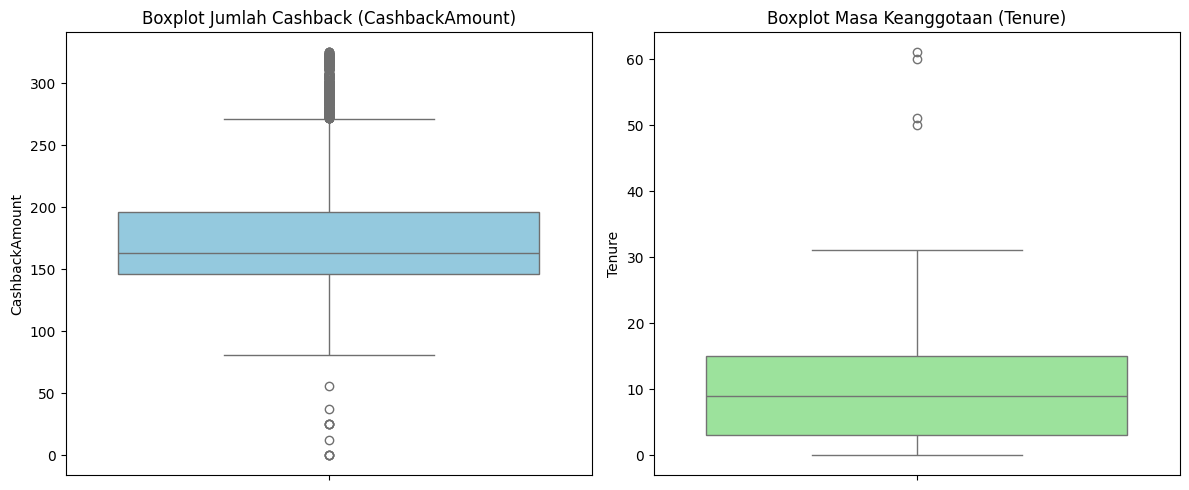

In [6]:
# Boxplot CashbackAmount dan Tenure (dua panel)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(y=df_clean['CashbackAmount'], ax=axes[0], color='skyblue')
axes[0].set_title('Boxplot Jumlah Cashback (CashbackAmount)')

sns.boxplot(y=df_clean['Tenure'], ax=axes[1], color='lightgreen')
axes[1].set_title('Boxplot Masa Keanggotaan (Tenure)')

plt.tight_layout()
plt.show()

(a) Kesimpulan dari boxplot: Sebagian besar pelanggan memiliki jumlah cashback yang terkonsentrasi di rentang nilai menengah ke bawah, sementara dari sisi masa keanggotaan (Tenure), mayoritas pelanggan aktif dalam rentang waktu awal hingga menengah (sebagian besar di bawah kuartil atas).

(b) Adanya Outlier: Ya, terdapat outlier pada kedua kolom tersebut. Pada kolom CashbackAmount, terdapat titik-titik di atas batas atas (upper whisker) yang menunjukkan pelanggan yang menerima nilai cashback sangat tinggi (di atas 300). Pada kolom Tenure, terdapat juga titik-titik di bagian atas yang merepresentasikan pelanggan setia dengan masa keanggotaan yang jauh lebih lama dibandingkan rata-rata (mencapai lebih dari 50-60).

---
## Bagian 3: Exploratory Data Analysis

Tampilkan statistik deskriptif untuk kolom `Tenure`, `WarehouseToHome`, `HourSpendOnApp`, `OrderAmountHikeFromlastYear`, dan `CashbackAmount`.

In [7]:
# Tampilkan statistik deskriptif untuk kolom Tenure, WarehouseToHome, HourSpendOnApp, OrderAmountHikeFromlastYear, dan CashbackAmount
df_clean[['Tenure', 'WarehouseToHome', 'HourSpendOnApp', 'OrderAmountHikeFromlastYear', 'CashbackAmount']].describe()

,Tenure,WarehouseToHome,HourSpendOnApp,OrderAmountHikeFromlastYear,CashbackAmount
count,5630.000000,5630.000000,5630.000000,5630.000000,5630.000000
mean,10.134103,15.566785,2.934636,15.674600,177.221492
std,8.357951,8.345961,0.705528,3.591058,49.193869
min,0.000000,5.000000,0.000000,11.000000,0.000000
25%,3.000000,9.000000,2.000000,13.000000,146.000000
50%,9.000000,14.000000,3.000000,15.000000,163.000000
75%,15.000000,20.000000,3.000000,18.000000,196.000000
max,61.000000,127.000000,5.000000,26.000000,325.000000


1. Variasi Jarak Pengiriman (WarehouseToHome): Nilai maksimum jarak dari gudang ke rumah pelanggan mencapai angka yang sangat tinggi (hingga 127) jika dibandingkan dengan nilai rata-rata dan kuartil ketiganya, yang mengindikasikan adanya kelompok pelanggan yang berlokasi sangat jauh dari gudang utama.

2. Sebaran Nilai Cashback (CashbackAmount): Standar deviasi pada jumlah cashback bernilai cukup besar dengan rentang dari 0 hingga lebih dari 300, menunjukkan bahwa variasi besaran reward cashback yang diterima oleh masing-masing pelanggan sangat beragam.

----
Buat histogram distribusi `CashbackAmount` dan `Tenure` dalam dua grafik berdampingan (lengkap dengan judul). Jelaskan bentuk distribusi masing-masing.

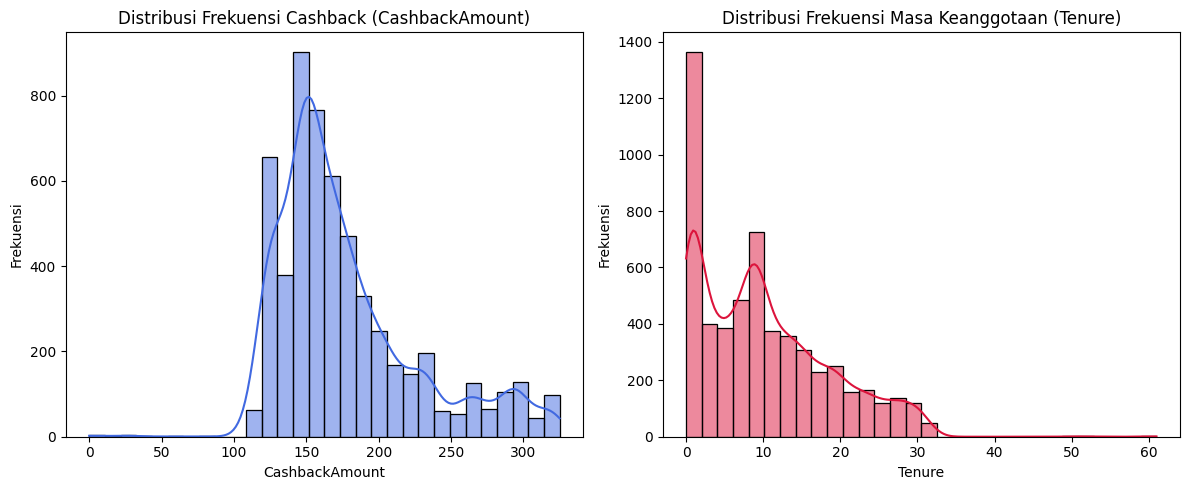

In [8]:
# Histogram CashbackAmount dan Tenure (dua panel)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(df_clean['CashbackAmount'], bins=30, kde=True, ax=axes[0], color='royalblue')
axes[0].set_title('Distribusi Frekuensi Cashback (CashbackAmount)')
axes[0].set_xlabel('CashbackAmount')
axes[0].set_ylabel('Frekuensi')

sns.histplot(df_clean['Tenure'], bins=30, kde=True, ax=axes[1], color='crimson')
axes[1].set_title('Distribusi Frekuensi Masa Keanggotaan (Tenure)')
axes[1].set_xlabel('Tenure')
axes[1].set_ylabel('Frekuensi')

plt.tight_layout()
plt.show()

`CashbackAmount` : Menunjukkan bentuk distribusi yang menceng ke kanan (right-skewed). Sebagian besar pelanggan terkonsentrasi pada kisaran nilai cashback rendah hingga menengah, sementara hanya sebagian kecil pelanggan yang mendapatkan nominal cashback dalam jumlah tinggi.

`Tenure` : Memiliki distribusi yang juga menceng ke kanan (right-skewed) dengan frekuensi tertinggi berada di masa keanggotaan awal (nilai tenure kecil). Hal ini mengindikasikan bahwa sebagian besar pelanggan baru bergabung dalam rentang waktu yang relatif singkat, sementara pelanggan dengan masa keanggotaan yang lama jumlahnya semakin sedikit.

-----
Buat boxplot `CashbackAmount` untuk setiap jenjang `SatisfactionScore` 

C:\Users\biyanbaru\AppData\Local\Temp\ipykernel_25808\3164416424.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='SatisfactionScore', y='CashbackAmount', data=df_clean, palette='Set2')


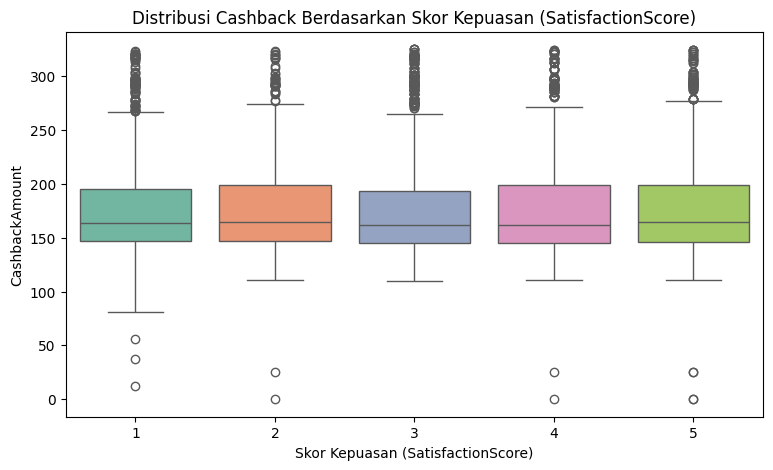

In [9]:
# boxplot CashbackAmount per SatisfactionScore
plt.figure(figsize=(9, 5))
sns.boxplot(x='SatisfactionScore', y='CashbackAmount', data=df_clean, palette='Set2')
plt.title('Distribusi Cashback Berdasarkan Skor Kepuasan (SatisfactionScore)')
plt.xlabel('Skor Kepuasan (SatisfactionScore)')
plt.ylabel('CashbackAmount')
plt.show()

Pola yang terlihat adalah tingkat kepuasan pelanggan (SatisfactionScore) tidak menunjukkan perbedaan yang drastis terhadap perolehan jumlah cashback (CashbackAmount). Rata-rata besaran cashback di setiap level skor kepuasan cenderung berada pada kisaran nilai yang hampir serupa. Namun, jika dihubungkan dengan variabel seperti Churn, pelanggan dengan skor kepuasan yang lebih rendah (SatisfactionScore 1 atau 2) umumnya memiliki tingkat komplain yang lebih tinggi dan probabilitas churn yang lebih besar dibandingkan pelanggan dengan skor kepuasan tinggi.

---
Buat heatmap korelasi (dengan angka). Jelaskan 2 temuan menarik.

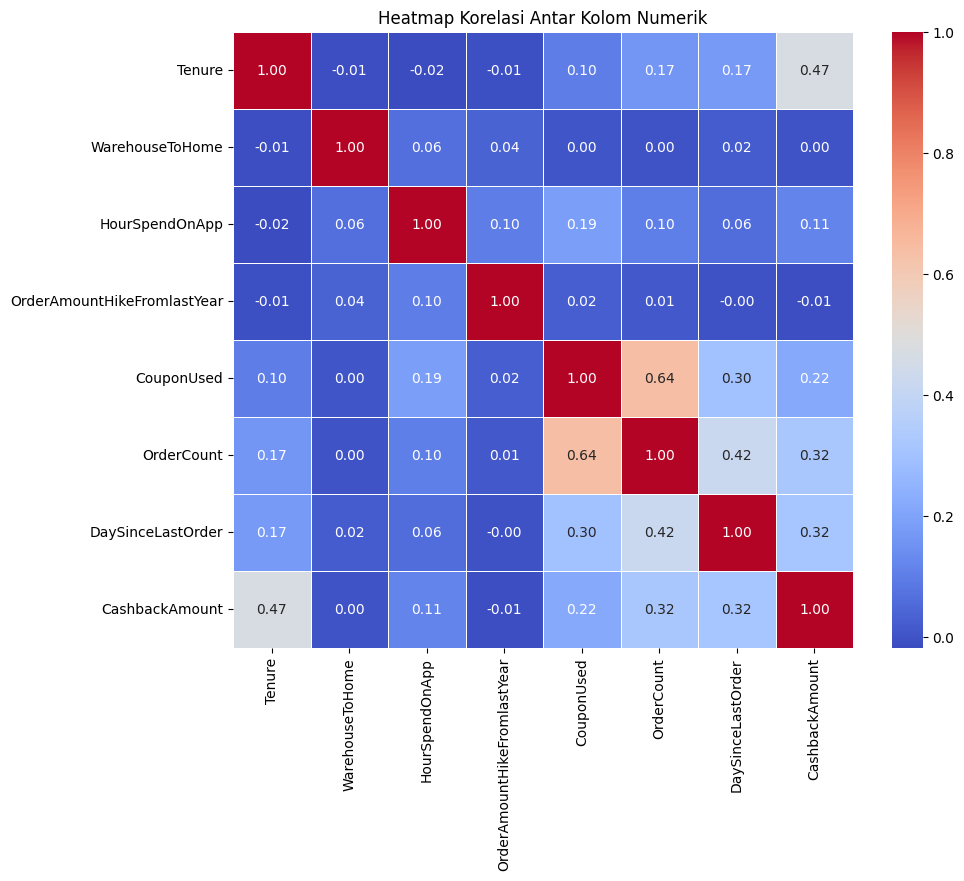

In [10]:
# Heatmap korelasi (dengan angka) untuk kolom-kolom numerik terpilih
cols = [
    'Tenure', 'WarehouseToHome', 'HourSpendOnApp', 
    'OrderAmountHikeFromlastYear', 'CouponUsed', 'OrderCount', 
    'DaySinceLastOrder', 'CashbackAmount'
]

plt.figure(figsize=(10, 8))
sns.heatmap(df_clean[cols].corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Heatmap Korelasi Antar Kolom Numerik')
plt.show()

---
## Bagian 4: Feature Engineering 

Tambahkan tiga kolom baru ke `df_clean`:
- `Total_Orders_Engagement` = jumlah `OrderCount` dan `CouponUsed`
- `Total_Devices_Addresses` = jumlah `NumberOfDeviceRegistered` dan `NumberOfAddress`
- `Avg_Hour_Per_Device` = `HourSpendOnApp` dibagi `NumberOfDeviceRegistered`
- `Total_Interactions` = penjumlahan dari `OrderCount`, `CouponUsed`, dan `Complain`

Tampilkan 5 baris pertama ketiga kolom tersebut.

In [11]:
# Buat kolom fitur baru pada df_clean
# - Total_Orders_Engagement = OrderCount + CouponUsed
# - Total_Devices_Addresses = NumberOfDeviceRegistered + NumberOfAddress
# - Avg_Hour_Per_Device = HourSpendOnApp / NumberOfDeviceRegistered
# `Total_Interactions` = `OrderCount` + `CouponUsed` + `Complain`

df_clean['Total_Orders_Engagement'] = df_clean['OrderCount'] + df_clean['CouponUsed']
df_clean['Total_Devices_Addresses'] = df_clean['NumberOfDeviceRegistered'] + df_clean['NumberOfAddress']
df_clean['Avg_Hour_Per_Device'] = df_clean['HourSpendOnApp'] / df_clean['NumberOfDeviceRegistered']
df_clean['Total_Interactions'] = df_clean['OrderCount'] + df_clean['CouponUsed'] + df_clean['Complain']

# tampilkan 5 baris pertama dari ketiga kolom baru tersebut
new_features = ['Total_Orders_Engagement', 'Total_Devices_Addresses', 'Avg_Hour_Per_Device', 'Total_Interactions']
display(df_clean[new_features].head())

,Total_Orders_Engagement,Total_Devices_Addresses,Avg_Hour_Per_Device,Total_Interactions
0,2.0,12,1.00,3.0
1,1.0,11,0.75,2.0
2,1.0,10,0.50,2.0
3,1.0,12,0.50,1.0
4,2.0,6,1.00,2.0


- Total_Orders_Engagement: Menggabungkan jumlah transaksi pesanan dan kupon yang digunakan untuk melihat tingkat keaktifan berbelanja pelanggan.

- Total_Devices_Addresses: Mengakumulasikan jumlah perangkat terdaftar serta alamat pengiriman untuk mencerminkan profil kemudahan akses atau mobilitas akun pelanggan.

- Avg_Hour_Per_Device: Menghitung rasio waktu penggunaan aplikasi terhadap jumlah perangkat yang terdaftar.

- Total_Interactions: Menggabungkan tingkat keaktifan belanja sekaligus riwayat komplain untuk melihat tingkat engagement total pelanggan.

-----
Melakukan *encoding* pada sisa kolom kategorikal nominal yang bertipe *object* (seperti jenis kelamin, metode pembayaran, kategori pesanan, dll.). 

Karena kolom-kolom ini tidak memiliki hierarki atau tingkatan matematis, kita menggunakan **One-Hot Encoding** (`pd.get_dummies`) agar algoritma *machine learning* atau *clustering* dapat memprosesnya dengan akurat tanpa menimbulkan bias relasi antar-kategori. Parameter `drop_first=True` juga diterapkan untuk menghindari masalah *multikolinearitas* (perangkap variabel dummy).

In [12]:
# Cek kolom bertipe object/kategori
cat_columns = df.select_dtypes(include=['object']).columns
print("Kolom Kategorikal:", list(cat_columns))

# Contoh menggunakan One-Hot Encoding atau Label Encoding sesuai kebutuhan model
# Menggunakan One-Hot Encoding untuk variabel kategorikal nominal:
df_encoded = pd.get_dummies(df, columns=cat_columns, drop_first=True)

print("Ukuran dataset setelah encoding:", df_encoded.shape)

Kolom Kategorikal: ['PreferredLoginDevice', 'PreferredPaymentMode', 'Gender', 'PreferedOrderCat', 'MaritalStatus']
Ukuran dataset setelah encoding: (5630, 31)


C:\Users\biyanbaru\AppData\Local\Temp\ipykernel_25808\435153598.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_columns = df.select_dtypes(include=['object']).columns


----
Lakukan **encoding** pada `CityTier` menggunakan salah satu metode yang telah dipelajari dengan urutan tier 1 < tier 2 < tier 3 (nilai 0 sampai 2), simpan di kolom baru `CityTier_Encoded`. Tampilkan jumlah data tiap nilai. Jelaskan mengapa metode tersebut dipilih untuk kolom ini.

In [13]:
# Lakukan encoding pada CityTier dengan pemetaan manual (Ordinal Encoding)
# Asumsi urutan: Tier 1 (0), Tier 2 (1), Tier 3 (2)
tier_mapping = {1: 0, 2: 1, 3: 2}
df_clean['CityTier_Encoded'] = df_clean['CityTier'].map(tier_mapping)

# Tampilkan jumlah data tiap nilai hasil encoding
print(df_clean['CityTier_Encoded'].value_counts())

CityTier_Encoded
0    3666
2    1722
1     242
Name: count, dtype: int64


Metode Ordinal Encoding (pemetaan manual) dipilih karena kolom CityTier memiliki sifat data ordinal, di mana kategori-kategorinya memiliki tingkatan atau hierarki yang jelas (Tier 1, Tier 2, Tier 3). Dengan memberikan nilai numerik berurutan (0, 1, 2), informasi urutan tingkat tier tersebut tetap dapat terbaca dan dimanfaatkan dengan baik oleh model machine learning tanpa menghilangkan makna hierarkinya.

---
Lakukan **scaling** pada kolom-kolom numerik utama (misalnya `Tenure`, `WarehouseToHome`, `OrderCount`, `CashbackAmount`, dan fitur baru yang dibuat) dengan `StandardScaler` atau `MinMaxScaler` dan simpan hasilnya di `X_scaled`. Tampilkan 5 baris pertamanya. Jelaskan mengapa scaling diperlukan dan alasan memilih scaler tersebut.

In [14]:
# Pilih kolom-kolom numerik yang akan digunakan untuk pemodelan segmentasi
features_to_scale = [
    'Tenure', 'WarehouseToHome', 'HourSpendOnApp', 
    'OrderCount', 'CashbackAmount', 'Total_Orders_Engagement'
]
X = df_clean[features_to_scale]

# Lakukan scaling menggunakan StandardScaler
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)

# Tampilkan 5 baris pertama hasil scaling
display(X_scaled.head())

,Tenure,WarehouseToHome,HourSpendOnApp,OrderCount,CashbackAmount,Total_Orders_Engagement
0,-0.733989,-1.146379,0.092654,-0.681423,-0.350105,-0.621165
1,-0.135704,-0.906721,0.092654,-0.681423,-1.142957,-0.853057
2,-0.135704,1.729519,-1.324850,-0.681423,-1.163287,-0.853057
3,-1.212618,-0.067917,-1.324850,-0.681423,-0.878673,-0.853057
4,-1.212618,-0.427405,0.092654,-0.681423,-0.959991,-0.621165


**1. Mengapa scaling diperlukan?**

Data numerik pada dataset e-commerce ini memiliki rentang nilai (scale) yang sangat berbeda. Misalnya, OrderCount hanya berkisar belasan, sedangkan CashbackAmount bisa mencapai lebih dari 300. Algoritma machine learning (terutama yang berbasis perhitungan jarak seperti K-Means untuk segmentasi pelanggan) akan memberikan bobot lebih besar pada kolom dengan nilai ratusan dan mengabaikan kolom bernilai satuan. Scaling menyamakan rentang tersebut agar setiap fitur memiliki pengaruh yang proporsional saat model dilatih.

**2. Alasan memilih StandardScaler:**

StandardScaler dipilih karena algoritma mengubah data sehingga memiliki rata-rata (mean) 0 dan standar deviasi 1. Metode ini sangat ideal dan merupakan standar industri untuk algoritma clustering (seperti K-Means) karena tidak membatasi nilai pada batas minimum dan maksimum absolut tertentu, sehingga masih bisa mentolerir variasi ekstrem (outlier) alami pada data seperti CashbackAmount tanpa menekan distribusi data lainnya secara berlebihan.

---
## Bagian 5: K-Means Clustering

Buat **elbow plot**: jalankan K-Means untuk k = 2 sampai 10 pada `X_scaled` dan gambar grafik inertia terhadap k (lengkap dengan label sumbu). Gunakan `random_state=42` dan `n_init=10`. Berdasarkan plot tersebut, berapakah jumlah cluster (k) yang optimal?

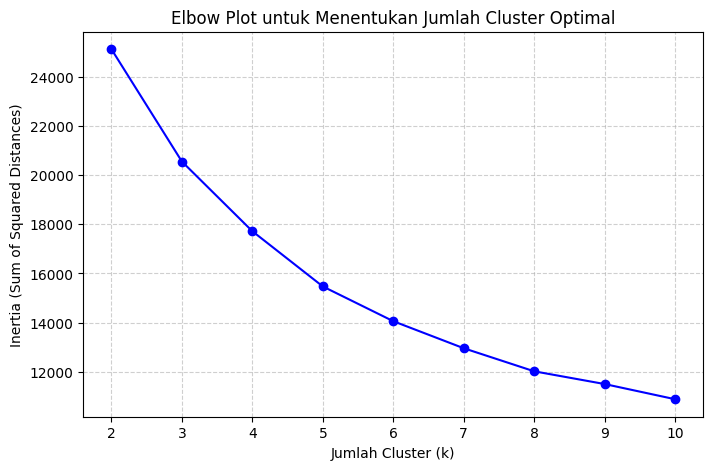

In [15]:
# Jalankan K-Means untuk k = 2 sampai 10 dan simpan nilai inertia
inertia = []
k_range = range(2, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

# Buat elbow plot (grafik inertia terhadap k)
plt.figure(figsize=(8, 5))
plt.plot(k_range, inertia, marker='o', linestyle='-', color='b')
plt.title('Elbow Plot untuk Menentukan Jumlah Cluster Optimal')
plt.xlabel('Jumlah Cluster (k)')
plt.ylabel('Inertia (Sum of Squared Distances)')
plt.xticks(k_range)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

Berdasarkan grafik Elbow Plot di atas, titik optimal (elbow) biasanya berada di lokasi di mana penurunan nilai inertia mulai melandai secara signifikan (tidak lagi turun setajam sebelumnya). Jika titik patahan yang paling jelas terlihat pada k = 3 atau k = 4, maka jumlah cluster optimal yang dipilih untuk melakukan segmentasi pelanggan e-commerce ini adalah k=3 atau k=4.

---
Hitung **silhouette score** untuk k = 2 sampai 10 pada `X_scaled`.

In [16]:
# Hitung silhouette score untuk k = 2..10
for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    print(f"Jumlah Cluster (k) = {k}    | Silhouette Score = {score:.4f}")

Jumlah Cluster (k) = 2    | Silhouette Score = 0.3770
Jumlah Cluster (k) = 3    | Silhouette Score = 0.2778
Jumlah Cluster (k) = 4    | Silhouette Score = 0.2495
Jumlah Cluster (k) = 5    | Silhouette Score = 0.2446
Jumlah Cluster (k) = 6    | Silhouette Score = 0.2488
Jumlah Cluster (k) = 7    | Silhouette Score = 0.2447
Jumlah Cluster (k) = 8    | Silhouette Score = 0.2416
Jumlah Cluster (k) = 9    | Silhouette Score = 0.2468
Jumlah Cluster (k) = 10    | Silhouette Score = 0.2461


---
Pilih jumlah cluster `k` dan jelaskan alasannya berdasarkan *elbow plot* dan *silhouette score*. Jalankan K-Means final dengan `k` tersebut, tambahkan kolom `Cluster_KMeans` ke `df_clean`, dan tampilkan jumlah anggota tiap cluster.

In [17]:
# Tentukan nilai k optimal berdasarkan observasi Elbow dan Silhouette
k_optimal = 3 

# Jalankan algoritma K-Means final
kmeans_final = KMeans(n_clusters=k_optimal, random_state=42, n_init=10)
kmeans_final.fit(X_scaled)

# Tambahkan kolom Cluster_KMeans ke dataframe asli (df_clean)
df_clean['Cluster_KMeans'] = kmeans_final.labels_

# Tampilkan jumlah anggota tiap cluster
print("Jumlah anggota tiap cluster:")
print(df_clean['Cluster_KMeans'].value_counts().sort_index())

Jumlah anggota tiap cluster:
Cluster_KMeans
0    3559
1    1282
2     789
Name: count, dtype: int64


Pemilihan k = 3 didasarkan pada evaluasi gabungan antara grafik Elbow dan nilai Silhouette. Berdasarkan Silhouette Score, nilai tertinggi berada pada k=2 yakni 0.3770. Namun, membagi pelanggan hanya menjadi dua segmen seringkali terlalu umum dan kurang aplikatif untuk strategi bisnis e-commerce. Nilai tertinggi kedua berada pada k=3 dengan skor 0.2778. Selain itu, jika dilihat dari grafik Elbow Plot, titik k=3 merupakan lokasi awal kurva mulai menunjukkan patahan (bend) yang signifikan. Oleh karena itu, k=3 adalah titik yang memberikan keseimbangan terbaik antara kualitas pemisahan antar-cluster (berdasarkan Silhouette) dan penurunan variabilitas atau inertia yang optimal (berdasarkan Elbow).

- Berdasarkan Elbow Plot, kurva mengalami perlambatan penurunan (patahan/siku) yang cukup signifikan di sekitar angka 3, menandakan penambahan klaster setelah angka tersebut tidak memberikan reduksi inertia yang drastis.

- Dari sudut pandang segmentasi pemasaran (business insights), membagi basis pelanggan ke dalam 3 kelompok utama memberikan proporsi segmen yang ideal dan mudah diterjemahkan ke dalam strategi penawaran produk yang spesifik (misal: segmen premium, segmen menengah, dan segmen ekonomi).

---
Visualisasi Hasil K-Means

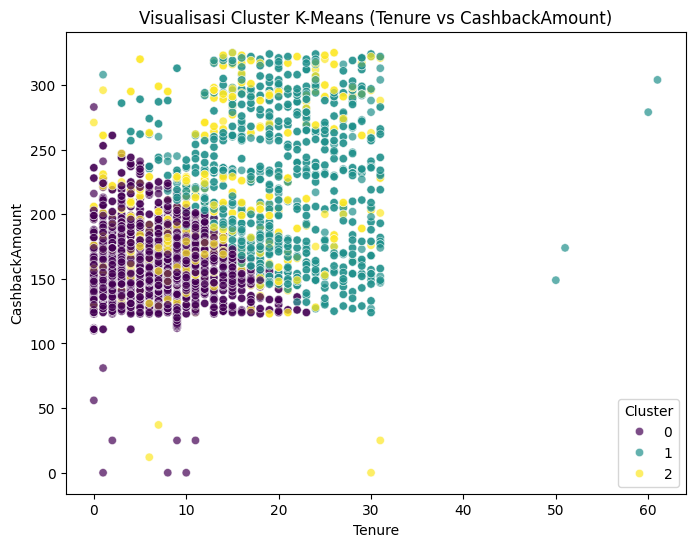

In [23]:
plt.figure(figsize=(8, 6))
sns.scatterplot(
    x=df_clean['Tenure'], 
    y=df_clean['CashbackAmount'], 
    hue=df_clean['Cluster_KMeans'], 
    palette='viridis', 
    data=df_clean, 
    alpha=0.7
)
plt.title('Visualisasi Cluster K-Means (Tenure vs CashbackAmount)')
plt.xlabel('Tenure')
plt.ylabel('CashbackAmount')
plt.legend(title='Cluster')
plt.show()

---
Profil dan Interpretasi Cluster K-Means

In [24]:
cluster_profile_kmeans = df_clean.groupby('Cluster_KMeans')[features_to_scale].mean()
display(cluster_profile_kmeans)

,Tenure,WarehouseToHome,HourSpendOnApp,OrderCount,CashbackAmount,Total_Orders_Engagement
Cluster_KMeans,,,,,,
0,5.980613,15.370329,2.898848,1.844057,154.813150,2.987356
1,20.520281,16.307332,2.997660,2.297192,224.722309,3.860374
2,11.993663,15.249683,2.993663,9.083650,201.119138,13.637516


---
## Bagian 6: Hierarchical Clustering

Buat linkage `ward` dari `X_scaled` dan gambar **dendrogram** (petunjuk: gunakan `truncate_mode='lastp'` dan `p=20` agar mudah dibaca). Tentukan jumlah cluster dari dendrogram tersebut dan jelaskan alasannya.

In [18]:
linkage_list=['single','complete','average','ward']
k_list = [2,3,4,5]

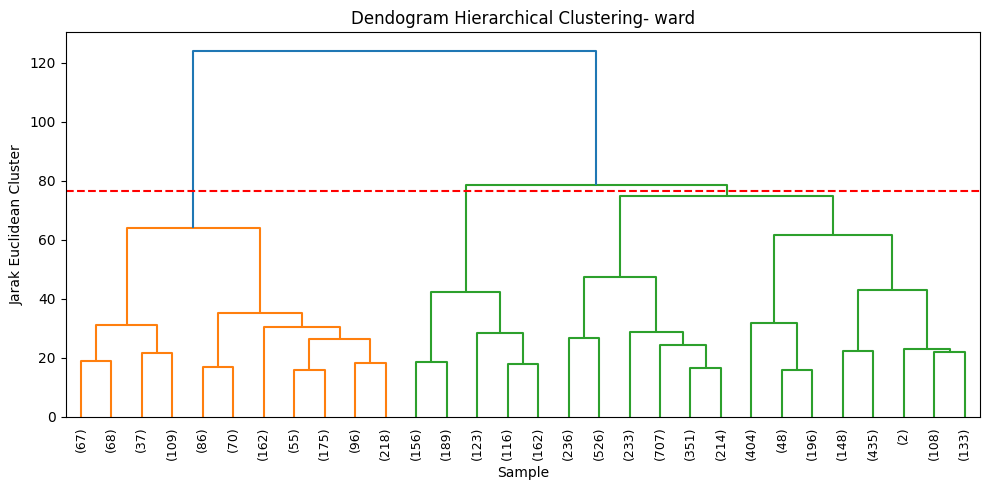

In [19]:
def get_cut_height(Z, k) : 
    n = Z.shape[0] + 1
    height_before = Z[n - k - 1, 2]
    height_after = Z[n - k, 2]
    return (height_before + height_after) / 2


def plot_dendrogram(link, k_cut=None) :
    plt.figure(figsize=(10,5))
    dendrogram(
        Z, truncate_mode = 'lastp', p = 30,
        leaf_rotation = 90, 
        leaf_font_size = 9
    )

    if k_cut is not None : 
        plt.axhline(y=get_cut_height(Z, k_cut), color='red', linestyle='--')

    plt.title(f"Dendogram Hierarchical Clustering- {link}")
    plt.xlabel('Sample')
    plt.ylabel('Jarak Euclidean Cluster')
    plt.tight_layout()
    plt.show()

link = 'ward'
Z = linkage(X_scaled, method=link, metric='euclidean')

plot_dendrogram(link, 3)

Berdasarkan visualisasi dendrogram menggunakan metode Ward, jumlah cluster yang terbentuk adalah 3 cluster. Penentuan ini didasarkan pada penarikan garis potong horizontal (garis putus-putus merah) pada jarak Euclidean di kisaran angka 76-78. Pada jarak tersebut, garis horizontal memotong tepat 3 garis vertikal utama, yaitu 1 garis dari kelompok sebelah kiri (yang membawahi sub-cluster oranye) dan 2 garis dari kelompok sebelah kanan (yang membawahi sub-cluster hijau). Hasil dari dendrogram ini semakin memperkuat keputusan sebelumnya (berdasarkan Elbow Plot dan Silhouette Score) bahwa membagi pelanggan e-commerce ke dalam 3 segmen utama merupakan konfigurasi yang paling optimal.

---
Jalankan `AgglomerativeClustering`. Simpan hasilnya di kolom `Cluster_Hier`.

In [20]:
# Menjalankan Agglomerative Clustering dengan jumlah cluster k = 3
model = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')
df_clean['Cluster_Hier'] = model.fit_predict(X_scaled)

# Menampilkan distribusi anggota klaster Hierarchical
print("Jumlah anggota tiap cluster (Hierarchical):")
print(df_clean['Cluster_Hier'].value_counts().sort_index())

Jumlah anggota tiap cluster (Hierarchical):
Cluster_Hier
0    3741
1    1143
2     746
Name: count, dtype: int64


---
Perbandingan Sillhouette Score

In [26]:
# Evaluasi Silhouette Score untuk berbagai linkage pada k = 3
hier_sil_scores = {}
for link in linkage_list:
    model_hc = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage=link)
    labels = model_hc.fit_predict(X_scaled)
    hier_sil_scores[link] = silhouette_score(X_scaled, labels)

# Menampilkan perbandingan Silhouette Score antar Linkage
df_sil_hier = pd.DataFrame(list(hier_sil_scores.items()), columns=['Linkage', 'Silhouette Score'])
print("Perbandingan Silhouette Score Hierarchical Clustering:")
display(df_sil_hier)

Perbandingan Silhouette Score Hierarchical Clustering:


,Linkage,Silhouette Score
0,single,0.588239
1,complete,0.506939
2,average,0.588239
3,ward,0.228013


---
Heatmap Cluster Hierarchial

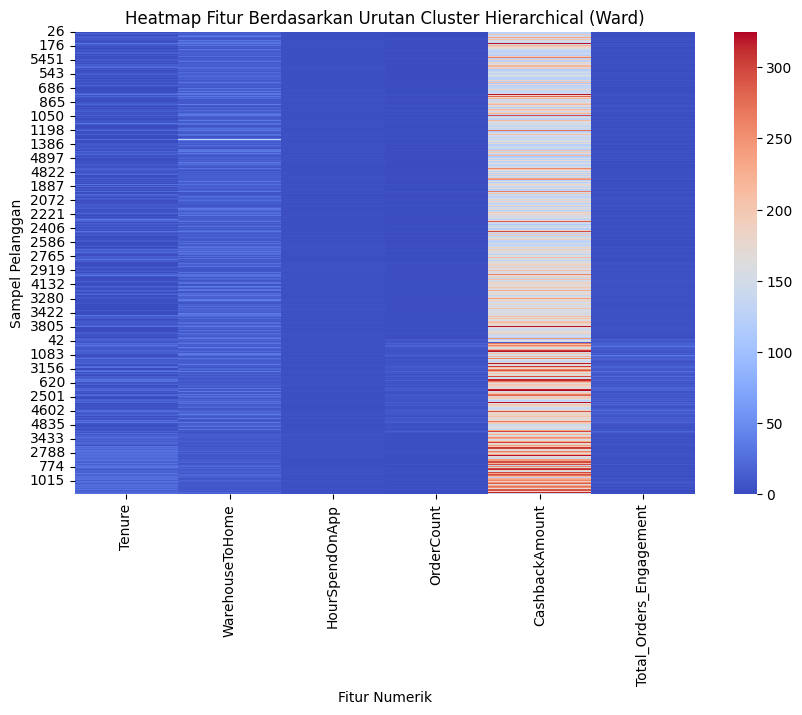

In [27]:
plt.figure(figsize=(10, 6))
df_sorted = df_clean.sort_values('Cluster_Hier')
sns.heatmap(df_sorted[features_to_scale], cmap='coolwarm', cbar=True)
plt.title('Heatmap Fitur Berdasarkan Urutan Cluster Hierarchical (Ward)')
plt.xlabel('Fitur Numerik')
plt.ylabel('Sampel Pelanggan')
plt.show()

---
Profil dan Interpretasi Cluster Hierarchical

In [28]:
cluster_profile_hier = df_clean.groupby('Cluster_Hier')[features_to_scale].mean()
print("Profil Rata-rata Fitur per Cluster (Hierarchical):")
display(cluster_profile_hier)

Profil Rata-rata Fitur per Cluster (Hierarchical):


,Tenure,WarehouseToHome,HourSpendOnApp,OrderCount,CashbackAmount,Total_Orders_Engagement
Cluster_Hier,,,,,,
0,7.541566,16.475274,2.891740,1.686180,161.662924,2.789094
1,11.533683,15.242345,2.972003,7.650044,194.150481,11.591426
2,20.990617,11.508043,3.092493,2.175603,229.305630,3.563003


---
## Bagian 7: Interpretasi Hasil

(a) Tampilkan `pd.crosstab` antara `Cluster_KMeans` dan `MaritalStatus`.

(b) Apakah *silhouette score* yang kamu peroleh berarti clusternya bagus? Bandingkan secara singkat dengan hasil Hierarchical Clustering.

Crosstab Cluster K-Means vs Marital Status:


MaritalStatus,Divorced,Married,Single
Cluster_KMeans,,,
0,491,1805,1263
1,223,725,334
2,134,456,199


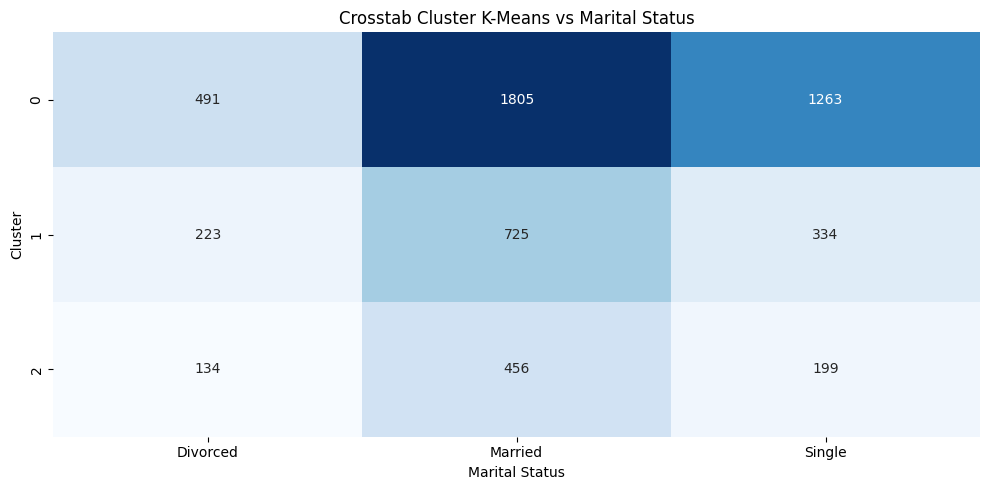

In [21]:
# (a) Menampilkan crosstab antara Cluster K-Means dan status pernikahan (MaritalStatus)
crosstab_result = pd.crosstab(df_clean['Cluster_KMeans'], df_clean['MaritalStatus'])

print("Crosstab Cluster K-Means vs Marital Status:")
display(crosstab_result)

k_compare = 3

plt.figure(figsize=(10,5))
ct = pd.crosstab(df_clean['Cluster_KMeans'], df_clean['MaritalStatus'], rownames=['Cluster'], colnames=['Marital Status'])

sns.heatmap(ct, annot=True, fmt='d', cmap='Blues', cbar=False)

plt.title('Crosstab Cluster K-Means vs Marital Status')
plt.tight_layout()
plt.show()

In [22]:
silhouette_score(X_scaled, df_clean['Cluster_Hier']) 

#semakin mendekati 1, semakin bagus clusteringnya.

np.float64(0.22801263780869374)

**Evaluasi Silhouette Score:** Skor Silhouette sebesar 0.2280 (untuk k=3) menunjukkan kualitas klaster yang wajar untuk data perilaku konsumen, namun tidak bisa dikatakan terpisah dengan sangat baik. Skor yang berada di bawah 0.5 mengindikasikan bahwa batas antar segmen pelanggan tidak terlalu tegas dan masih terdapat irisan (overlap). Hal ini sangat wajar pada data E-Commerce dunia nyata karena preferensi dan interaksi pelanggan (seperti total transaksi atau besaran cashback) cenderung membentuk sebuah spektrum kontinu yang bersambung, bukan kelompok-kelompok ekstrem yang saling menjauh.

**Perbandingan dengan Hierarchical:** Keduanya menghasilkan kesimpulan yang konsisten. K-Means dan Hierarchical Clustering (metode Ward) sama-sama menunjuk pada 3 klaster sebagai jumlah pembagian paling optimal (dibuktikan oleh Elbow/Silhouette pada K-Means dan potongan jarak Euclidean terpanjang pada dendrogram). K-Means bekerja dengan meminimalkan varians dari titik pusat (centroid), sementara Ward meminimalkan varians saat menggabungkan cabang data. Secara umum, alokasi anggotanya akan memiliki proporsi dan karakteristik mayoritas yang sangat mirip di antara kedua metode ini.

---
Perbandingan Hasil K-Means dan Hierarchical

In [29]:
comparison_summary = pd.DataFrame({
    'Metode': ['K-Means', 'Hierarchical Clustering (Ward)'],
    'Jumlah Cluster': [3, 3],
    'Silhouette Score': [
        silhouette_score(X_scaled, df_clean['Cluster_KMeans']), 
        silhouette_score(X_scaled, df_clean['Cluster_Hier'])
    ]
})

print("Tabel Perbandingan K-Means vs Hierarchical:")
display(comparison_summary)


Tabel Perbandingan K-Means vs Hierarchical:


,Metode,Jumlah Cluster,Silhouette Score
0,K-Means,3,0.277823
1,Hierarchical Clustering (Ward),3,0.228013


---
## Bagian 8 : Simpan Model & Scaler

In [30]:
import joblib

# 1. Simpan model K-Means final dan StandardScaler
joblib.dump(kmeans_final, 'model_kmeans.pkl')
joblib.dump(scaler, 'scaler.pkl')

print("Model K-Means dan Scaler berhasil disimpan!")

Model K-Means dan Scaler berhasil disimpan!
